# Project Deliverable 1: Data Collection, Cleaning, and Exploration

**Name:** Todd Simonson
**Course:** MSCS-634: Advanced Big Data and Data Mining
**Instructor:** Dr. Satish Penmatsa
**Project:** Advanced Data Mining for Data-Driven Insights and Predictive Modeling

**Dataset:** CMS Nursing Home Care Compare, Provider Information (October 2026 release)

## 1. Dataset Selection and Description

### Source

The Centers for Medicare & Medicaid Services (CMS) publishes the Provider Information file as part of its Nursing Home Care Compare program. The file is refreshed monthly; this project uses the release with a processing date of October 1, 2026.

* Dataset page: https://data.cms.gov/provider-data/dataset/4pq5-n9py
* File used: `NH_ProviderInfo_Oct2026.csv`

### What each record represents

Each row is one nursing home that is currently certified to participate in Medicare, Medicaid, or both. The file contains **14,686 nursing homes** and **102 attributes**, covering all 50 states, Washington DC, Puerto Rico, and Guam.

### Attribute groups

| Group | Example attributes | Role in this project |
|---|---|---|
| Identity and location | CCN (CMS Certification Number), name, address, state, county, urban flag, latitude/longitude | Identification, geographic analysis |
| Ownership and structure | Ownership type, chain name and size, provider type, hospital-based flag, continuing care retirement community | Key explanatory features |
| Size and census | Certified beds, average residents per day | Facility size, occupancy |
| Star ratings (1 to 5) | Overall, health inspection, quality measure (QM), staffing | Quality outcomes |
| Staffing | Reported nurse aide, LPN, RN, and total nurse hours per resident per day; case-mix and adjusted versions; weekend hours | Regression target and features |
| Turnover | Total nursing staff turnover, RN turnover, administrator departures | Workforce stability |
| Inspections | Deficiency counts and scores for the last three survey cycles, weighted health survey score | Quality outcomes |
| Enforcement | Number of fines, total fines in dollars, payment denials, penalties | Quality outcomes |
| Status flags | Abuse icon, Special Focus Facility status, high-performing icon | Classification targets |
| Footnotes | One footnote column per rating or measure | Explain why a value is missing |

### Why this dataset fits the project

1. **Size and attributes.** 14,686 records and 102 attributes far exceed the 500-record and 8-10-attribute minimums.
2. **Healthcare domain.** Healthcare is one of the suggested domains, and nursing home quality is a real public-policy problem. The facilities in this file report a combined average of about 1.25 million residents per day.
3. **Natural targets for every later deliverable.**
   * **Regression (Deliverable 2):** reported total nurse staffing hours per resident per day is a continuous outcome.
   * **Classification (Deliverable 3):** the abuse icon is a yes/no flag that CMS assigns to facilities cited for abuse.
   * **Clustering (Deliverable 3):** facilities can be segmented by ownership, size, staffing, and quality.
   * **Association rules (Deliverable 3):** ownership type, chain membership, and binned ratings and staffing levels form natural "items."
4. **Real data quality problems.** The file has structurally missing values with documented reasons, inconsistent text formatting, values that are physically impossible, and heavily skewed measures. Each requires a deliberate cleaning decision.
5. **Ethical depth (Deliverable 4).** The data concerns a vulnerable population and raises questions about profit motives in care, the fairness of public star ratings, and how rural and urban facilities are compared.

## 2. Setup and Data Loading

In [1]:
# core libraries for data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# show more columns and wider output so wide tables are readable
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

# consistent plot style for every figure in the notebook
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

### A loading pitfall: leading zeros

ZIP codes and CCNs are identifiers, not numbers. If pandas is allowed to guess their type, it reads ZIP codes as integers and silently drops leading zeros. The cell below shows the damage before loading the file correctly.

In [2]:
RAW_PATH = 'data/raw/NH_ProviderInfo_Oct2026.csv'

# default load: pandas guesses that zip code is an integer
naive = pd.read_csv(RAW_PATH, low_memory=False)
short_zips = (naive['ZIP Code'].astype(str).str.len() < 5).sum()
print('zip code dtype with default load:', naive['ZIP Code'].dtype)
print('zip codes that lost a leading zero:', short_zips)
print(naive.loc[naive['State'] == 'CT', ['Provider Name', 'ZIP Code', 'Location']].head(3))

zip code dtype with default load: int64
zip codes that lost a leading zero: 1145
                                     Provider Name  ZIP Code                                    Location
1457             AUTUMN LAKE HEALTHCARE AT WINDSOR      6095          581 POQUONOCK AVE,WINDSOR,CT,06095
1458  MONTOWESE CENTER FOR HEALTH & REHABILITATION      6473  163 QUINNIPIAC AVENUE,NORTH HAVEN,CT,06473
1459           AUTUMN LAKE HEALTHCARE AT GLEN HILL      6811             1 GLEN HILL RD,DANBURY,CT,06811


In [3]:
# correct load: read identifier columns as text so leading zeros are preserved
raw = pd.read_csv(RAW_PATH, low_memory=False,
                  dtype={'CMS Certification Number (CCN)': str, 'ZIP Code': str})
print('zip code dtype:', raw['ZIP Code'].dtype)
print('zip codes shorter than 5 characters:', (raw['ZIP Code'].str.len() < 5).sum())
del naive

zip code dtype: str
zip codes shorter than 5 characters: 0


## 3. Inspecting the Structure

In [4]:
# overall size of the dataset
print('rows:', raw.shape[0])
print('columns:', raw.shape[1])
print()

# how many columns pandas read as numbers versus text
print(raw.dtypes.astype(str).value_counts())

rows: 14686
columns: 102

float64    71
str        26
int64       5
Name: count, dtype: int64


In [5]:
# first five rows, transposed so all 102 column names are visible
raw.head().T

,0,1,2,3,4
CMS Certification Number (CCN),015009,015010,015012,015014,015015
Provider Name,"BURNS NURSING HOME, INC.",COOSA VALLEY HEALTHCARE CENTER,HIGHLANDS HEALTH AND REHAB,THE HEALTHCARE CENTER OF EASTVIEW,PLANTATION MANOR NURSING HOME
Provider Address,701 MONROE STREET NW,260 WEST WALNUT STREET,380 WOODS COVE ROAD,7755 FOURTH AVENUE SOUTH,6450 OLD TUSCALOOSA HIGHWAY
City/Town,RUSSELLVILLE,SYLACAUGA,SCOTTSBORO,BIRMINGHAM,MC CALLA
State,AL,AL,AL,AL,AL
...,...,...,...,...,...
Location,"701 MONROE STREET NW,RUSSELLVILLE,AL,35653","260 WEST WALNUT STREET,SYLACAUGA,AL,35150","380 WOODS COVE ROAD,SCOTTSBORO,AL,35768","7755 FOURTH AVENUE SOUTH,BIRMINGHAM,AL,35206","6450 OLD TUSCALOOSA HIGHWAY,MC CALLA,AL,35111"
Latitude,34.5149,33.1637,34.6611,33.5595,33.3222
Longitude,-87.736,-86.254,-86.047,-86.722,-87.034
Geocoding Footnote,NaN,NaN,NaN,NaN,NaN


Column names in the raw file are long and contain spaces, slashes, and parentheses. They are converted to lowercase snake_case so they can be referenced reliably in code. The original names are kept in a lookup table.

In [6]:
import re

def to_snake(name):
    # lowercase, replace any run of non-alphanumeric characters with one underscore
    s = re.sub(r'[^0-9a-zA-Z]+', '_', name.strip().lower())
    return s.strip('_')

df = raw.copy()
name_map = {c: to_snake(c) for c in df.columns}
df = df.rename(columns=name_map)

# spot-check a few renamed columns
pd.Series(name_map).iloc[[0, 10, 33, 50, 96]]

CMS Certification Number (CCN)                                                cms_certification_number_ccn
Ownership Type                                                                              ownership_type
Overall Rating                                                                              overall_rating
Reported Licensed Staffing Hours per Resident per Day    reported_licensed_staffing_hours_per_resident_...
Total Number of Penalties                                                        total_number_of_penalties
dtype: str

## 4. Data Cleaning

Cleaning proceeds in five parts: duplicates, inconsistent data, missing values, noisy data, and selection of the analysis columns. Every change is counted so the effect of each step is visible.

### 4.1 Duplicates

Three levels of duplication are checked:

1. Exact duplicate rows.
2. Duplicate facility IDs. The CCN should be unique to each certified facility.
3. Duplicate physical locations. Two rows at the same address could be the same facility entered twice.

In [7]:
# level 1: identical rows
print('exact duplicate rows:', df.duplicated().sum())

# level 2: repeated facility id
print('duplicate ccns:', df['cms_certification_number_ccn'].duplicated().sum())

# level 3: repeated full address (street, city, state, zip)
same_loc = df[df.duplicated('location', keep=False)].sort_values('location')
print('rows sharing an address with another row:', len(same_loc))
same_loc[['cms_certification_number_ccn', 'provider_name', 'location',
          'number_of_certified_beds', 'provider_resides_in_hospital']]

exact duplicate rows: 0
duplicate ccns: 0
rows sharing an address with another row: 16


,cms_certification_number_ccn,provider_name,location,number_of_certified_beds,provider_resides_in_hospital
13078,525592,CARE & REHAB - LADYSMITH 1,"1001 E 11TH ST N,LADYSMITH,WI,54848",32.0,N
13153,525710,CARE & REHAB - LADYSMITH 2,"1001 E 11TH ST N,LADYSMITH,WI,54848",30.0,N
13679,555880,CLEAR VIEW CONVALESCENT CENTER,"15823 SO. WESTERN AVE.,GARDENA,CA,90247",99.0,N
13680,555881,CLEAR VIEW SANITARIUM,"15823 SO. WESTERN AVE.,GARDENA,CA,90247",73.0,N
11324,425074,C M Tucker Jr Nursing Care Center Fewell and S...,"2200 Harden Street,Columbia,SC,29203",252.0,N
11439,425360,C M Tucker Jr Nursing Care Center Roddey Pav...,"2200 Harden Street,Columbia,SC,29203",308.0,N
10688,395328,BRETHREN VILLAGE,"3001 LITITZ PIKE,LANCASTER,PA,17606",120.0,N
11197,396140,REHABILITATION CENTER AT BRETHREN VILLAGE LLC,"3001 LITITZ PIKE,LANCASTER,PA,17606",20.0,N
6851,25A197,Jnh-Jaquith Inn,"3550 HIGHWAY 468 WEST,WHITFIELD,MS,39193",45.0,N
6857,25A404,JNH-MADISON INN,"3550 HIGHWAY 468 WEST,WHITFIELD,MS,39193",63.0,N


**Decision: keep all rows.** No exact duplicates or repeated CCNs exist. The 16 rows that share an address are 8 pairs of separately certified units in the same building or campus. Each pair has different CCNs, different names, and different bed counts (for example, "CARE & REHAB - LADYSMITH 1" and "... 2", or a nursing home and a children's hospital unit at the same Toms River address). CMS rates them as independent facilities, so merging them would combine two distinct operations.

In [8]:
# repeated names are also checked, since common names could hide duplicates
dup_names = df[df.duplicated('provider_name', keep=False)]
print('rows whose name appears more than once:', len(dup_names))
print('of those, distinct states involved:', dup_names['state'].nunique())
dup_names.groupby('provider_name')['state'].agg(lambda s: ', '.join(sorted(s))).head(8)

rows whose name appears more than once: 215
of those, distinct states involved: 40


provider_name
ALEXANDRIA CARE CENTER                                CA, IN
APOSTOLIC CHRISTIAN HOME                              IL, KS
AURORA HEALTH AND REHABILITATION                      MO, MS
Absolut Center for Nursing and Rehabilitation at A    NY, NY
BEACHSIDE POST ACUTE                                  CA, CA
BEACON HILL                                           IL, TX
BEACON RIDGE                                          OK, PA
BELMONT HEALTHCARE CENTER                             CA, WV
Name: state, dtype: str

Repeated names are generic names reused in different places (for example, the same "Heritage" or "Manor" name in several states), not duplicate records. No rows are removed.

### 4.2 Inconsistent Data

The following problems are corrected:

* **Text case and spacing.** Provider names and cities mix ALL CAPS and Title Case, and some names contain double spaces.
* **Yes/No fields** are stored as `'Y'`/`'N'` text and are converted to true booleans.
* **Ownership type** combines a sector and a legal form in one string (for example, "For profit - Limited Liability company"). It is split into two columns.
* **Placeholder text.** The sprinkler field uses the string "Data Not Available" instead of a true missing value.
* **Dates** are stored as text.

In [9]:
# text case and whitespace before the fix
mixed_case = (df['provider_name'] != df['provider_name'].str.upper()).sum()
double_space = df['provider_name'].str.contains('  ').sum()
print('provider names not in all caps:', mixed_case)
print('provider names with double spaces:', double_space)
print('city names not in all caps:', (df['city_town'] != df['city_town'].str.upper()).sum())
df.loc[df['provider_name'].str.contains('  '), 'provider_name'].head(3).tolist()

provider names not in all caps: 5126
provider names with double spaces: 76
city names not in all caps: 3907


['EVERSTEAD HEALTH AND REHABILITATION  CENTER',
 'PINE HILL REHABILITATION AND WELLNESS  CENTER',
 'ALTOONA  HEALTH & REHAB']

In [10]:
# standardize: uppercase, collapse repeated spaces, trim the ends
for col in ['provider_name', 'legal_business_name', 'city_town', 'chain_name']:
    df[col] = (df[col].str.upper()
                      .str.replace(r'\s+', ' ', regex=True)
                      .str.strip())

print('provider names not in all caps after fix:', (df['provider_name'] != df['provider_name'].str.upper()).sum())
print('double spaces after fix:', df['provider_name'].str.contains('  ').sum())

provider names not in all caps after fix: 0
double spaces after fix: 0


In [11]:
# convert y/n text flags to booleans
yn_cols = ['urban', 'provider_resides_in_hospital', 'continuing_care_retirement_community',
           'abuse_icon', 'high_performing_icon',
           'most_recent_health_inspection_more_than_2_years_ago',
           'provider_changed_ownership_in_last_12_months']
for col in yn_cols:
    print(col, sorted(df[col].dropna().unique()))
    df[col] = df[col].map({'Y': True, 'N': False})

urban ['N', 'Y']
provider_resides_in_hospital ['N', 'Y']
continuing_care_retirement_community ['N', 'Y']
abuse_icon ['N', 'Y']
high_performing_icon ['N', 'Y']
most_recent_health_inspection_more_than_2_years_ago ['N', 'Y']
provider_changed_ownership_in_last_12_months ['N', 'Y']


In [12]:
# split ownership type into sector and legal form
parts = df['ownership_type'].str.split(' - ', n=1, expand=True)
df['ownership_sector'] = parts[0]
df['ownership_form'] = parts[1]
pd.crosstab(df['ownership_form'], df['ownership_sector'])

ownership_sector,For profit,Government,Non profit
ownership_form,,,
Church related,0,0,240
City,0,49,0
City/county,0,71,0
Corporation,4601,0,2304
County,0,341,0
Federal,0,14,0
Hospital district,0,316,0
Individual,603,0,0
Limited Liability company,5333,0,0


In [13]:
# placeholder text becomes a real missing value
print('before:', df['automatic_sprinkler_systems_in_all_required_areas'].value_counts().to_dict())
df['automatic_sprinkler_systems_in_all_required_areas'] = (
    df['automatic_sprinkler_systems_in_all_required_areas'].replace('Data Not Available', np.nan))
print('after: ', df['automatic_sprinkler_systems_in_all_required_areas'].value_counts(dropna=False).to_dict())

before: {'Yes': 14599, 'Data Not Available': 51, 'Partial': 36}
after:  {'Yes': 14599, nan: 51, 'Partial': 36}


In [14]:
# parse text dates into datetime values
date_cols = ['date_first_approved_to_provide_medicare_and_medicaid_services',
             'rating_cycle_1_standard_survey_health_date',
             'rating_cycle_2_standard_health_survey_date', 'processing_date']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

df[date_cols].agg(['min', 'max']).T

,min,max
date_first_approved_to_provide_medicare_and_medicaid_services,1967-01-01,2026-08-21
rating_cycle_1_standard_survey_health_date,2019-10-03,2026-09-23
rating_cycle_2_standard_health_survey_date,2018-09-06,2026-04-17
processing_date,2026-10-01,2026-10-01


### 4.3 Missing Values

#### Missing-value report

In [15]:
# share of missing values in every column that has any
missing = df.isna().sum()
missing_report = (pd.DataFrame({'missing': missing, 'percent': (missing / len(df) * 100).round(1)})
                    .query('missing > 0')
                    .sort_values('percent', ascending=False))
print('columns with at least one missing value:', len(missing_report), 'of', df.shape[1])
missing_report

columns with at least one missing value: 73 of 104


,missing,percent
rating_cycle_2_standard_survey_footnote,14682,100.0
average_number_of_residents_per_day_footnote,14628,99.6
overall_rating_footnote,14560,99.1
rating_cycle_1_standard_survey_footnote,14557,99.1
health_inspection_rating_footnote,14560,99.1
...,...,...
rating_cycle_1_number_of_health_revisits,39,0.3
rating_cycle_1_health_deficiency_score,39,0.3
rating_cycle_1_number_of_complaint_health_deficiencies,39,0.3
rating_cycle_1_number_of_standard_health_deficiencies,39,0.3


columns shown (at least 1% missing): 52


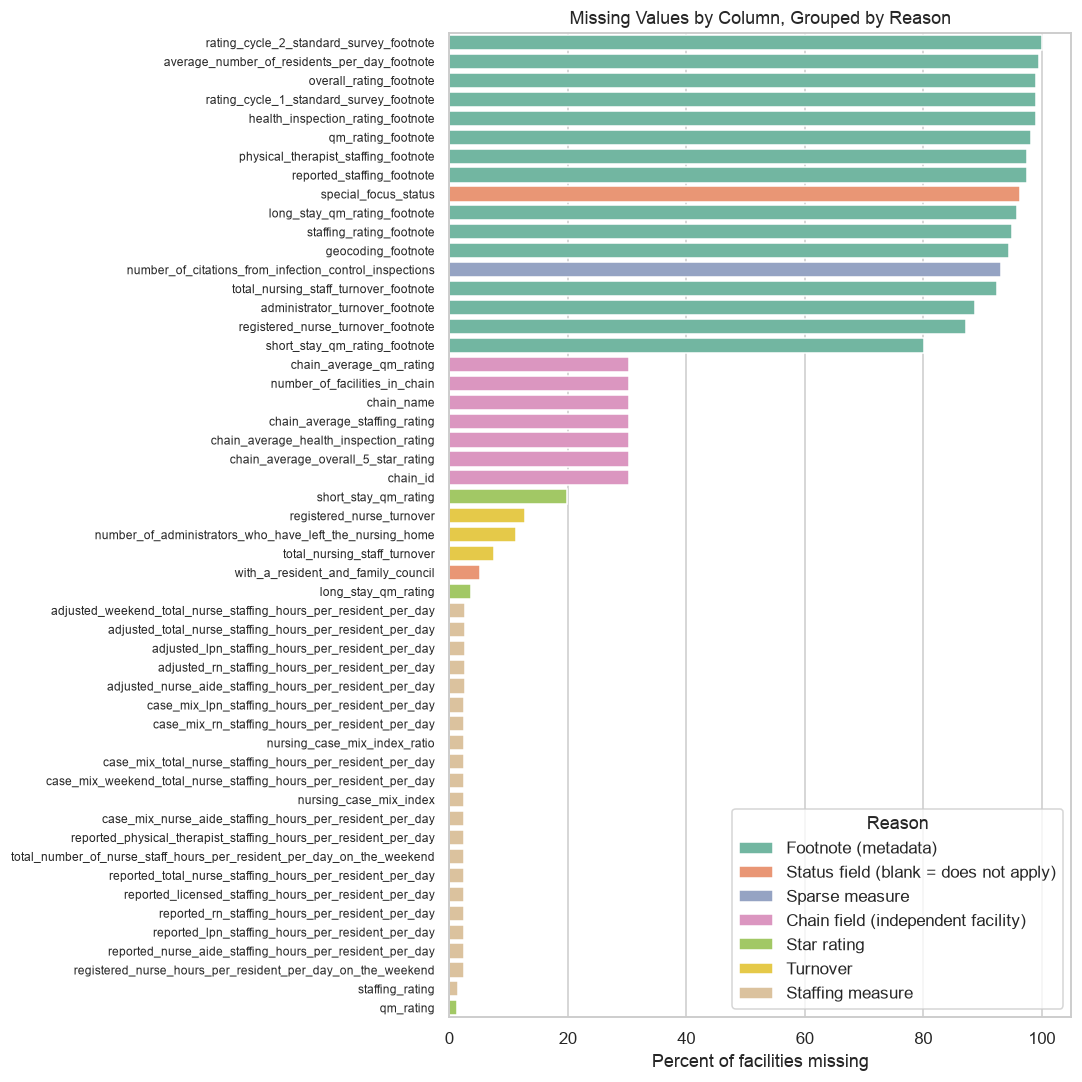

In [16]:
# group each column with missing values into the reason it is missing
def missing_group(col):
    if 'footnote' in col:
        return 'Footnote (metadata)'
    if col.startswith('chain_') or col == 'number_of_facilities_in_chain':
        return 'Chain field (independent facility)'
    if 'staffing' in col or 'case_mix' in col or 'hours_per_resident' in col:
        return 'Staffing measure'
    if 'rating' in col and 'cycle' not in col:
        return 'Star rating'
    if 'turnover' in col or 'administrators' in col:
        return 'Turnover'
    if col in ('special_focus_status', 'with_a_resident_and_family_council'):
        return 'Status field (blank = does not apply)'
    return 'Sparse measure'

# columns under 1% missing are left off the chart to keep it readable
plot_df = (missing_report.query('percent >= 1')
             .assign(group=lambda t: [missing_group(c) for c in t.index])
             .reset_index(names='column'))
print('columns shown (at least 1% missing):', len(plot_df))

plt.figure(figsize=(10, 10))
sns.barplot(data=plot_df, y='column', x='percent', hue='group', dodge=False, palette='Set2')
plt.xlabel('Percent of facilities missing')
plt.ylabel('')
plt.title('Missing Values by Column, Grouped by Reason')
plt.legend(title='Reason', loc='lower right')
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

**Insight:** 73 of the 104 columns have at least one missing value, but the chart shows the gaps fall into a few clear groups rather than being scattered at random. The 15 footnote columns are 80 to 100% empty because a footnote only appears when a value cannot be reported, so these columns are metadata, not data. The 7 chain columns are all missing for exactly the same 30.4% of facilities, the independent nursing homes. The staffing measures are missing together for about 2.5% of facilities, the same ones each time. Because values in each group are missing for one shared reason, each group gets one treatment decision instead of being handled column by column.

#### Using the footnotes to explain missing values

CMS attaches a footnote code when it cannot report a value. The codes relevant here are defined in the CMS Nursing Home Care Compare data dictionary (summarized at https://www.snfdata.com/definitions/quality_footnote.html):

| Code | Meaning |
|---|---|
| 1 | Newly certified nursing home with less than 12-15 months of data available |
| 6 | Facility submitted data that did not meet the criteria required to calculate a staffing measure |
| 18 | Facility is not rated due to a history of serious quality issues and is in the Special Focus Facility (SFF) program |
| 23 | Facility did not submit staffing data |
| 25 | The accuracy of the staffing data could not be validated by CMS |

In [17]:
# why is the overall rating missing
print('overall rating missing:', df['overall_rating'].isna().sum())
print(df.loc[df['overall_rating'].isna(), 'overall_rating_footnote'].value_counts().to_dict())

# footnote 18 should line up exactly with the special focus facilities
pd.crosstab(df['special_focus_status'].fillna('Not SFF'),
            df['overall_rating_footnote'].fillna(0).astype(int),
            rownames=['special_focus_status'], colnames=['overall_rating_footnote'])

overall rating missing: 126
{18.0: 87, 1.0: 39}


overall_rating_footnote,0,1,18
special_focus_status,,,
Not SFF,14120,39,0
SFF,0,0,87
SFF Candidate,440,0,0


In [18]:
# why are the staffing measures missing
staff_col = 'reported_total_nurse_staffing_hours_per_resident_per_day'
print('reported total staffing missing:', df[staff_col].isna().sum())
df.loc[df[staff_col].isna(), 'reported_staffing_footnote'].value_counts().to_dict()

reported total staffing missing: 367


{25.0: 160, 23.0: 122, 6.0: 85}

The footnotes account for every missing rating and staffing value:

* **Overall rating (126 missing).** 87 facilities are Special Focus Facilities (footnote 18), which CMS deliberately does not rate, and 39 are newly certified (footnote 1). These values were never measured, so **they are not imputed**. Filling in a star rating CMS refused to assign would invent a quality judgment. These facilities will be excluded from any model that uses the overall rating.
* **Staffing (367 missing).** Facilities either did not submit staffing data (23), submitted data CMS could not validate (25), or submitted data that did not meet the criteria (6). Total staffing is the planned regression target for Deliverable 2, and **a target should never be imputed**, because the model would then be trained partly on invented answers. These rows are kept in the cleaned file but will be dropped when the regression model is built.

Once their information is captured in the decisions above, the footnote columns themselves are dropped.

In [19]:
footnote_cols = [c for c in df.columns if 'footnote' in c]
df = df.drop(columns=footnote_cols)
print('footnote columns dropped:', len(footnote_cols))
print('remaining columns:', df.shape[1])

footnote columns dropped: 15
remaining columns: 89


#### Structurally missing values: filling with a meaningful constant

Some blanks are not unknown values; they mean "does not apply."

* **Chain fields (30.4% missing):** an empty chain name means the facility is independent. A `chain_member` flag is created, the chain size is set to 1 (the facility itself), and the chain-average ratings stay empty because there is no chain to average.
* **Special Focus Status (96.4% missing):** an empty value means the facility is not in the program.
* **Resident and family council (5.2% missing):** the field lists the councils a facility has (resident, or both resident and family). An empty value means no council was reported.

In [20]:
df['chain_member'] = df['chain_id'].notna()
df['number_of_facilities_in_chain'] = df['number_of_facilities_in_chain'].fillna(1)
df['special_focus_status'] = df['special_focus_status'].fillna('Not SFF')
df['with_a_resident_and_family_council'] = df['with_a_resident_and_family_council'].fillna('None reported')

print('chain members:', df['chain_member'].sum(), ' independent:', (~df['chain_member']).sum())
print(df['special_focus_status'].value_counts().to_dict())
print(df['with_a_resident_and_family_council'].value_counts().to_dict())

chain members: 10227  independent: 4459
{'Not SFF': 14159, 'SFF Candidate': 440, 'SFF': 87}
{'Resident': 12141, 'Both': 1786, 'None reported': 759}


#### Columns that are mostly empty: removal

`number_of_citations_from_infection_control_inspections` is 93.2% empty. The column contains real zeros (713 facilities), so an empty cell does not mean zero citations. It means no infection-control inspection took place in the reporting window. With that little coverage, the column cannot be imputed reliably and is dropped.

In [21]:
print(df['number_of_citations_from_infection_control_inspections'].value_counts(dropna=False).head(5).to_dict())
df = df.drop(columns=['number_of_citations_from_infection_control_inspections'])

{nan: 13685, 0.0: 713, 1.0: 141, 2.0: 66, 3.0: 37}


#### Feature gaps: median imputation with a missing-value flag

The turnover measures are missing for 7.5% to 12.8% of facilities, usually because the facility did not submit enough payroll data. Turnover will be an explanatory feature rather than a target, so these gaps are imputed. Median imputation is used because the distributions are skewed, and medians are computed within each ownership sector, since turnover differs by sector. A flag column records which values were imputed, so later models can test whether missingness itself carries a signal.

In [22]:
turnover_cols = ['total_nursing_staff_turnover', 'registered_nurse_turnover',
                 'number_of_administrators_who_have_left_the_nursing_home']

print('missing before:', df[turnover_cols].isna().sum().to_dict())
for col in turnover_cols:
    df[col + '_was_missing'] = df[col].isna()
    df[col] = df[col].fillna(df.groupby('ownership_sector')[col].transform('median'))
print('missing after: ', df[turnover_cols].isna().sum().to_dict())

# the sector medians that were used
df.groupby('ownership_sector')[turnover_cols].median().round(1)

missing before: {'total_nursing_staff_turnover': 1099, 'registered_nurse_turnover': 1876, 'number_of_administrators_who_have_left_the_nursing_home': 1653}
missing after:  {'total_nursing_staff_turnover': 0, 'registered_nurse_turnover': 0, 'number_of_administrators_who_have_left_the_nursing_home': 0}


,total_nursing_staff_turnover,registered_nurse_turnover,number_of_administrators_who_have_left_the_nursing_home
ownership_sector,,,
For profit,46.1,42.9,0.0
Government,42.1,33.3,0.0
Non profit,40.1,33.3,0.0


#### Rows missing facility size: removal

A small number of facilities have no certified bed count or average daily census. Size is needed to calculate occupancy and to compare facilities fairly, and the affected rows are under 0.5% of the data, so they are removed rather than imputed.

In [23]:
size_cols = ['number_of_certified_beds', 'average_number_of_residents_per_day']
print('missing:', df[size_cols].isna().sum().to_dict())
before = len(df)
df = df.dropna(subset=size_cols).reset_index(drop=True)
print(f'rows removed: {before - len(df)} ({(before - len(df)) / before:.2%}), rows remaining: {len(df)}')

missing: {'number_of_certified_beds': 11, 'average_number_of_residents_per_day': 58}
rows removed: 66 (0.45%), rows remaining: 14620


### 4.4 Noisy Data

Noisy values are those that are recorded but implausible. Two checks are applied: values that are physically impossible, and statistical outliers.

#### Occupancy above capacity

Occupancy is the average daily census divided by the number of certified beds. A value slightly above 1 can come from bed counts changing during the reporting period, but a value far above 1 is a data error.

In [24]:
df['occupancy_rate'] = df['average_number_of_residents_per_day'] / df['number_of_certified_beds']

over_100 = (df['occupancy_rate'] > 1.0).sum()
over_120 = (df['occupancy_rate'] > 1.2).sum()
print('facilities with more residents than beds:', over_100)
print('facilities above 120% occupancy:', over_120)
df.loc[df['occupancy_rate'] > 1.2, ['provider_name', 'state', 'number_of_certified_beds',
       'average_number_of_residents_per_day', 'occupancy_rate']].sort_values('occupancy_rate', ascending=False).head(8)

facilities with more residents than beds: 122
facilities above 120% occupancy: 32


,provider_name,state,number_of_certified_beds,average_number_of_residents_per_day,occupancy_rate
13555,VILLA DEL RIO,CA,12.0,159.5,13.291667
1440,"ACCEL AT LONGMONT HEALTH AND REHAB, LLC",CO,5.0,58.5,11.700000
4973,"BATON ROUGE GENERAL MEDICAL CENTER, SNF",LA,2.0,22.4,11.200000
8553,SAPPHIRE NURSING AND REHAB AT GOSHEN,NY,24.0,110.8,4.616667
13649,COLUSA MEDICAL CENTER - SNF,CA,6.0,16.3,2.716667
4423,MEADOWBROOK REHABILITATION HOSPITAL,KS,42.0,104.6,2.490476
3494,THRIVE OF LISLE,IL,28.0,67.6,2.414286
12725,UNITED TRANSITIONAL CARE CENTER,WV,32.0,58.5,1.828125


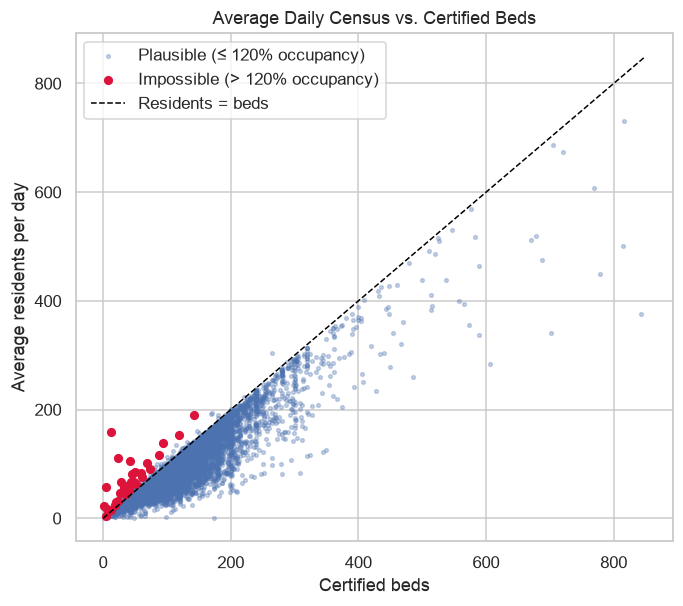

In [25]:
fig, ax = plt.subplots(figsize=(7, 6))
ok = df['occupancy_rate'] <= 1.2
ax.scatter(df.loc[ok, 'number_of_certified_beds'], df.loc[ok, 'average_number_of_residents_per_day'],
           s=6, alpha=0.3, label='Plausible (≤ 120% occupancy)')
ax.scatter(df.loc[~ok, 'number_of_certified_beds'], df.loc[~ok, 'average_number_of_residents_per_day'],
           s=25, color='crimson', label='Impossible (> 120% occupancy)')
lim = [0, 850]
ax.plot(lim, lim, color='black', linestyle='--', linewidth=1, label='Residents = beds')
ax.set_xlabel('Certified beds')
ax.set_ylabel('Average residents per day')
ax.set_title('Average Daily Census vs. Certified Beds')
ax.legend()
plt.show()

**Decision:** occupancy above 120% is treated as a recording error in either the bed count or the census. For those facilities, `occupancy_rate` is set to missing. The rows themselves are kept, because their ratings, inspections, and fines are unaffected by the error. Facilities between 100% and 120% are kept as recorded.

In [26]:
df.loc[df['occupancy_rate'] > 1.2, 'occupancy_rate'] = np.nan
print('occupancy values set to missing:', df['occupancy_rate'].isna().sum())
print(df['occupancy_rate'].describe().round(3))

occupancy values set to missing: 32
count    14588.000
mean         0.806
std          0.152
min          0.008
25%          0.725
50%          0.853
75%          0.922
max          1.197
Name: occupancy_rate, dtype: float64


#### Implausible staffing levels

Total nurse staffing hours per resident per day (HPRD) cluster tightly: the middle 98% of facilities fall between about 2.5 and 7.5 hours. A handful report values that cannot describe a functioning nursing home. Some report under 1.5 hours, which is less than 90 minutes of nursing care per resident per day, and one reports 0.04 hours. Two report more than 12 hours: a hospital-based unit with 3.5 residents and a specialized facility. These values are almost certainly reporting errors, or they come from facilities so atypical that they would distort a model of ordinary nursing homes.

In [27]:
staff_cols = [c for c in df.columns if 'staffing_hours' in c or 'hours_per_resident' in c]
s = df[staff_col]
print(s.quantile([0.01, 0.25, 0.5, 0.75, 0.99]).round(2).to_dict())

implausible = (s < 1.5) | (s > 12)
print('facilities below 1.5 hprd:', (s < 1.5).sum())
print('facilities above 12 hprd: ', (s > 12).sum())
df.loc[implausible, ['provider_name', 'state', 'average_number_of_residents_per_day', staff_col]].sort_values(staff_col).head(10)

{0.01: 2.46, 0.25: 3.37, 0.5: 3.71, 0.75: 4.22, 0.99: 7.47}
facilities below 1.5 hprd: 30
facilities above 12 hprd:  2


,provider_name,state,average_number_of_residents_per_day,reported_total_nurse_staffing_hours_per_resident_per_day
10383,SEILING NURSING CENTER,OK,17.8,0.00400
12989,BETHANY HOME,WI,87.3,0.03358
10855,"ROLLING FIELDS, INC",PA,41.8,0.03676
2415,APPLING NURSING AND REHABILITATION PAVILION,GA,94.3,0.03687
5224,LAFON NURSING FACILITY OF THE HOLY FAMILY,LA,80.5,0.11679
5187,AVOYELLES MANOR NURSING HOME,LA,55.3,0.19235
9596,PATASKALA OAKS CARE CENTER,OH,57.4,0.20964
6881,MAPLE LAWN NURSING HOME,MO,64.6,0.41782
13122,WYOMING RETIREMENT CENTER,WY,65.4,0.44397
6981,ARBOR VIEW NURSING AND REHABILITATION,MO,99.5,0.45313


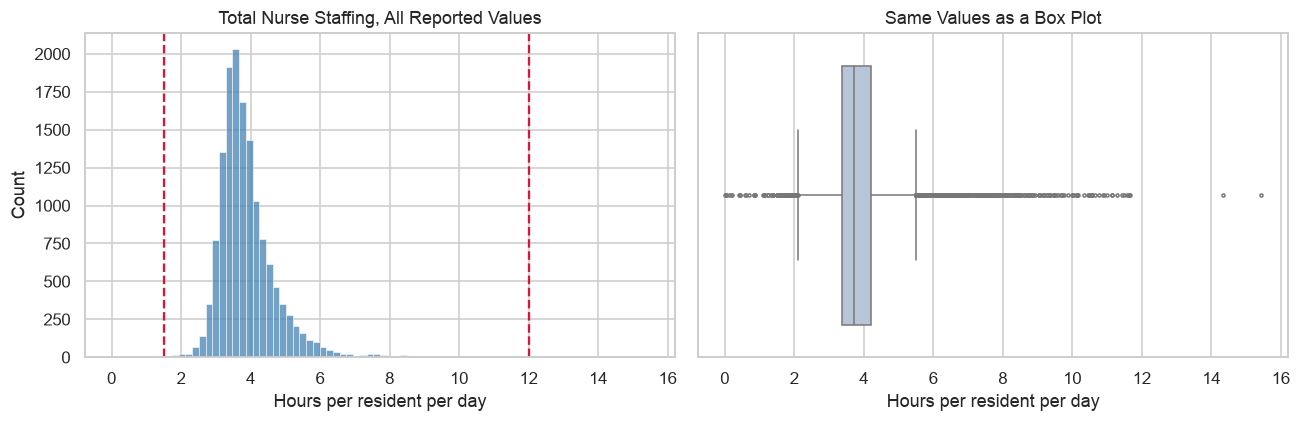

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(s.dropna(), bins=80, ax=axes[0], color='steelblue')
for x in (1.5, 12):
    axes[0].axvline(x, color='crimson', linestyle='--')
axes[0].set_title('Total Nurse Staffing, All Reported Values')
axes[0].set_xlabel('Hours per resident per day')

sns.boxplot(x=s.dropna(), ax=axes[1], color='lightsteelblue', fliersize=2)
axes[1].set_title('Same Values as a Box Plot')
axes[1].set_xlabel('Hours per resident per day')
plt.tight_layout()
plt.show()

**Decision:** staffing values below 1.5 or above 12 HPRD are set to missing in every staffing column for those facilities, so they will be excluded from the regression target along with the facilities CMS could not validate. The box plot also shows many points beyond the standard 1.5 × IQR whiskers, mostly on the high side. Those are **kept**: values of 5 to 8 hours are realistic for facilities with sicker residents or hospital-based units. Removing them would erase the facilities that staff best, which is exactly the variation Deliverable 2 needs to explain.

In [29]:
df.loc[implausible, staff_cols] = np.nan
q1, q3 = df[staff_col].quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = ((df[staff_col] < q1 - 1.5 * iqr) | (df[staff_col] > q3 + 1.5 * iqr)).sum()
print('staffing values set to missing as implausible:', implausible.sum())
print(f'iqr bounds kept for reference: {q1 - 1.5 * iqr:.2f} to {q3 + 1.5 * iqr:.2f} hprd, {iqr_outliers} facilities outside (kept)')

staffing values set to missing as implausible: 32
iqr bounds kept for reference: 2.10 to 5.49 hprd, 709 facilities outside (kept)


#### Skewed enforcement and inspection measures

Fines, penalties, and inspection scores are not errors, but they are extremely right-skewed. Most facilities have no fines, while a few have fines above $1 million. A log transform, log(1 + x), is added for these measures, so later models and plots are not dominated by a handful of extreme facilities. The original values are kept.

In [30]:
skewed = ['total_amount_of_fines_in_dollars', 'total_weighted_health_survey_score', 'number_of_fines']
print(df[skewed].skew().round(2).to_dict())
for col in skewed:
    df['log_' + col] = np.log1p(df[col])
print(df[['log_' + c for c in skewed]].skew().round(2).to_dict())

{'total_amount_of_fines_in_dollars': 4.3, 'total_weighted_health_survey_score': 3.66, 'number_of_fines': 2.89}
{'log_total_amount_of_fines_in_dollars': 0.3, 'log_total_weighted_health_survey_score': -0.66, 'log_number_of_fines': 1.0}


### 4.5 Selecting the Analysis Columns

Many of the remaining columns are not useful for analysis. Address, phone number, and legal name are identifiers. Others repeat information already captured elsewhere, such as the location string and the rating-cycle detail columns, which are summarized by the weighted survey score. A curated set of columns with short names is kept, along with two simple derived features: facility age and chain membership.

In [31]:
# years since first medicare/medicaid certification, measured at the processing date
df['facility_age_years'] = ((df['processing_date'] - df['date_first_approved_to_provide_medicare_and_medicaid_services'])
                            .dt.days / 365.25).round(1)

keep = {
    'cms_certification_number_ccn': 'ccn',
    'provider_name': 'name',
    'state': 'state',
    'zip_code': 'zip',
    'latitude': 'latitude',
    'longitude': 'longitude',
    'urban': 'urban',
    'ownership_sector': 'ownership_sector',
    'ownership_form': 'ownership_form',
    'provider_type': 'provider_type',
    'provider_resides_in_hospital': 'hospital_based',
    'continuing_care_retirement_community': 'ccrc',
    'chain_member': 'chain_member',
    'number_of_facilities_in_chain': 'chain_size',
    'number_of_certified_beds': 'beds',
    'average_number_of_residents_per_day': 'residents',
    'occupancy_rate': 'occupancy_rate',
    'facility_age_years': 'facility_age_years',
    'overall_rating': 'overall_rating',
    'health_inspection_rating': 'inspection_rating',
    'qm_rating': 'qm_rating',
    'staffing_rating': 'staffing_rating',
    'reported_total_nurse_staffing_hours_per_resident_per_day': 'total_nurse_hprd',
    'reported_rn_staffing_hours_per_resident_per_day': 'rn_hprd',
    'reported_lpn_staffing_hours_per_resident_per_day': 'lpn_hprd',
    'reported_nurse_aide_staffing_hours_per_resident_per_day': 'aide_hprd',
    'total_number_of_nurse_staff_hours_per_resident_per_day_on_the_weekend': 'weekend_nurse_hprd',
    'nursing_case_mix_index': 'case_mix_index',
    'total_nursing_staff_turnover': 'nurse_turnover',
    'registered_nurse_turnover': 'rn_turnover',
    'number_of_administrators_who_have_left_the_nursing_home': 'admin_departures',
    'total_nursing_staff_turnover_was_missing': 'nurse_turnover_was_missing',
    'total_weighted_health_survey_score': 'survey_score',
    'rating_cycle_1_total_number_of_health_deficiencies': 'deficiencies_recent',
    'number_of_fines': 'fines_count',
    'total_amount_of_fines_in_dollars': 'fines_dollars',
    'total_number_of_penalties': 'penalties',
    'log_total_amount_of_fines_in_dollars': 'log_fines_dollars',
    'log_total_weighted_health_survey_score': 'log_survey_score',
    'abuse_icon': 'abuse_icon',
    'special_focus_status': 'special_focus_status',
    'high_performing_icon': 'high_performing',
}

# the weekend column name is long and gets truncated by some exports, so it is matched by prefix
weekend = [c for c in df.columns if c.startswith('total_number_of_nurse_staff_hours_per_resident_per_day_on')]
keep[weekend[0]] = keep.pop('total_number_of_nurse_staff_hours_per_resident_per_day_on_the_weekend')

clean = df[list(keep)].rename(columns=keep)

# star ratings are whole numbers from 1 to 5, stored as nullable integers so missing values stay missing
for col in ['overall_rating', 'inspection_rating', 'qm_rating', 'staffing_rating']:
    clean[col] = clean[col].astype('Int64')
print('columns before selection:', df.shape[1])
print('columns after selection: ', clean.shape[1])
clean.head()

columns before selection: 97
columns after selection:  42


,ccn,name,state,zip,latitude,longitude,urban,ownership_sector,ownership_form,provider_type,hospital_based,ccrc,chain_member,chain_size,beds,residents,occupancy_rate,facility_age_years,overall_rating,inspection_rating,...,total_nurse_hprd,rn_hprd,lpn_hprd,aide_hprd,case_mix_index,nurse_turnover,rn_turnover,admin_departures,nurse_turnover_was_missing,survey_score,deficiencies_recent,fines_count,fines_dollars,penalties,log_fines_dollars,log_survey_score,abuse_icon,special_focus_status,high_performing,weekend_nurse_hprd
0,015009,"BURNS NURSING HOME, INC.",AL,35653,34.5149,-87.736,False,For profit,Corporation,Medicare and Medicaid,False,False,False,1.0,57.0,50.0,0.877193,57.1,2,2,...,3.94651,0.91121,0.53462,2.50068,1.37373,41.8,28.6,0.0,False,44.0,4.0,0,0.0,0,0.0,3.806662,False,Not SFF,False,3.17630
1,015010,COOSA VALLEY HEALTHCARE CENTER,AL,35150,33.1637,-86.254,False,For profit,Corporation,Medicare and Medicaid,False,False,True,5.0,85.0,75.1,0.883529,59.7,5,5,...,4.34659,0.88153,0.80967,2.65539,1.31587,44.9,8.3,0.0,False,1.0,0.0,0,0.0,0,0.0,0.693147,False,Not SFF,False,3.55152
2,015012,HIGHLANDS HEALTH AND REHAB,AL,35768,34.6611,-86.047,False,Government,County,Medicare and Medicaid,False,False,True,3.0,50.0,44.7,0.894000,59.7,5,4,...,4.70372,1.17322,0.74309,2.78742,1.30713,39.3,41.7,0.0,False,5.0,0.0,0,0.0,0,0.0,1.791759,False,Not SFF,False,3.72681
3,015014,THE HEALTHCARE CENTER OF EASTVIEW,AL,35206,33.5595,-86.722,True,For profit,Individual,Medicare and Medicaid,False,False,True,347.0,92.0,79.8,0.867391,59.7,2,2,...,3.43174,0.62981,0.72657,2.07536,1.38121,38.3,14.3,0.0,False,26.0,4.0,0,0.0,0,0.0,3.295837,False,Not SFF,False,2.80516
4,015015,PLANTATION MANOR NURSING HOME,AL,35111,33.3222,-87.034,True,For profit,Corporation,Medicare and Medicaid,False,False,False,1.0,103.0,95.9,0.931068,55.3,3,3,...,3.29334,0.43710,0.70556,2.15068,1.10890,40.5,25.0,3.0,False,20.0,5.0,0,0.0,0,0.0,3.044522,False,Not SFF,False,3.17818


### 4.6 Cleaning Summary

In [32]:
summary = pd.DataFrame({
    'raw file': [raw.shape[0], raw.shape[1], int(raw.isna().sum().sum())],
    'cleaned file': [clean.shape[0], clean.shape[1], int(clean.isna().sum().sum())],
}, index=['rows', 'columns', 'missing cells'])
summary

,raw file,cleaned file
rows,14686,14620
columns,102,42
missing cells,285857,2653


In [33]:
# remaining missing values are deliberate: unrated facilities, unreported staffing, and flagged errors
remaining = clean.isna().sum()
remaining[remaining > 0].sort_values(ascending=False)

total_nurse_hprd       340
rn_hprd                340
lpn_hprd               340
aide_hprd              340
weekend_nurse_hprd     340
case_mix_index         308
staffing_rating        164
qm_rating              160
overall_rating         110
inspection_rating      110
occupancy_rate          32
survey_score            23
deficiencies_recent     23
log_survey_score        23
dtype: int64

In [34]:
clean.to_csv('data/nh_cleaned.csv', index=False)
print('saved data/nh_cleaned.csv', clean.shape)

saved data/nh_cleaned.csv (14620, 42)


## 5. Exploratory Data Analysis

The EDA focuses on the three outcomes the later deliverables will model: **staffing** (regression), the **abuse icon** (classification), and the **star ratings** (quality context for clustering and association rules).

### 5.1 How are facilities rated?

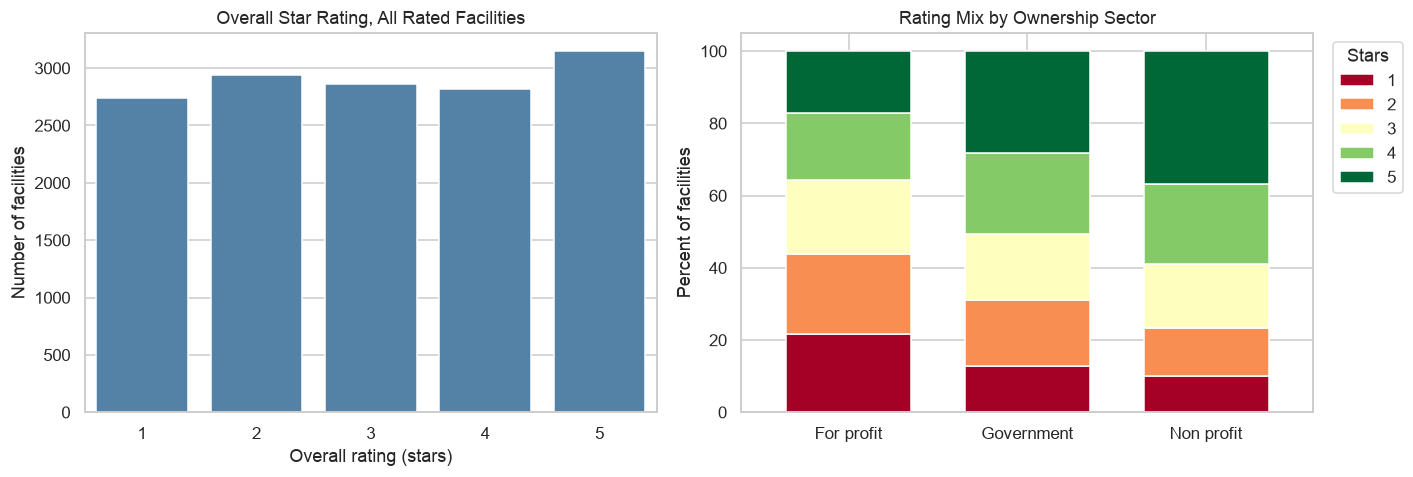

{np.int64(1): 18.9, np.int64(2): 20.3, np.int64(3): 19.8, np.int64(4): 19.4, np.int64(5): 21.7}


,count,mean,pct_stars_1,pct_stars_5
ownership_sector,,,,
For profit,10746,2.87,21.7,17.2
Government,929,3.35,12.8,28.3
Non profit,2835,3.62,9.9,36.7


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

order = [1, 2, 3, 4, 5]
sns.countplot(data=clean, x='overall_rating', order=order, ax=axes[0], color='steelblue')
axes[0].set_title('Overall Star Rating, All Rated Facilities')
axes[0].set_xlabel('Overall rating (stars)')
axes[0].set_ylabel('Number of facilities')

share = (pd.crosstab(clean['ownership_sector'], clean['overall_rating'], normalize='index') * 100)
share.plot(kind='bar', stacked=True, ax=axes[1], colormap='RdYlGn', width=0.7)
axes[1].set_title('Rating Mix by Ownership Sector')
axes[1].set_xlabel('')
axes[1].set_ylabel('Percent of facilities')
axes[1].legend(title='Stars', bbox_to_anchor=(1.02, 1), loc='upper left')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

print(clean['overall_rating'].value_counts(normalize=True).sort_index().mul(100).round(1).to_dict())
pd.concat([clean.groupby('ownership_sector')['overall_rating'].agg(['count', 'mean']).round(2),
           share[[1, 5]].round(1).add_prefix('pct_stars_')], axis=1)

**Insight:** Overall ratings are spread almost evenly across the five levels (18.9% to 21.7% each). This is consistent with CMS's method, which grades health inspections relative to other facilities in the same state, so a 3-star rating means "middle of its state," not a fixed national standard. Ownership sector separates sharply: 21.7% of for-profit facilities have 1 star and 17.2% have 5 stars, while for non-profit facilities the pattern reverses (9.9% with 1 star, 36.7% with 5 stars). Mean ratings are 2.87 for for-profit, 3.35 for government, and 3.62 for non-profit facilities. Ownership sector will be a central feature in every later model.

### 5.2 Staffing: the Deliverable 2 target

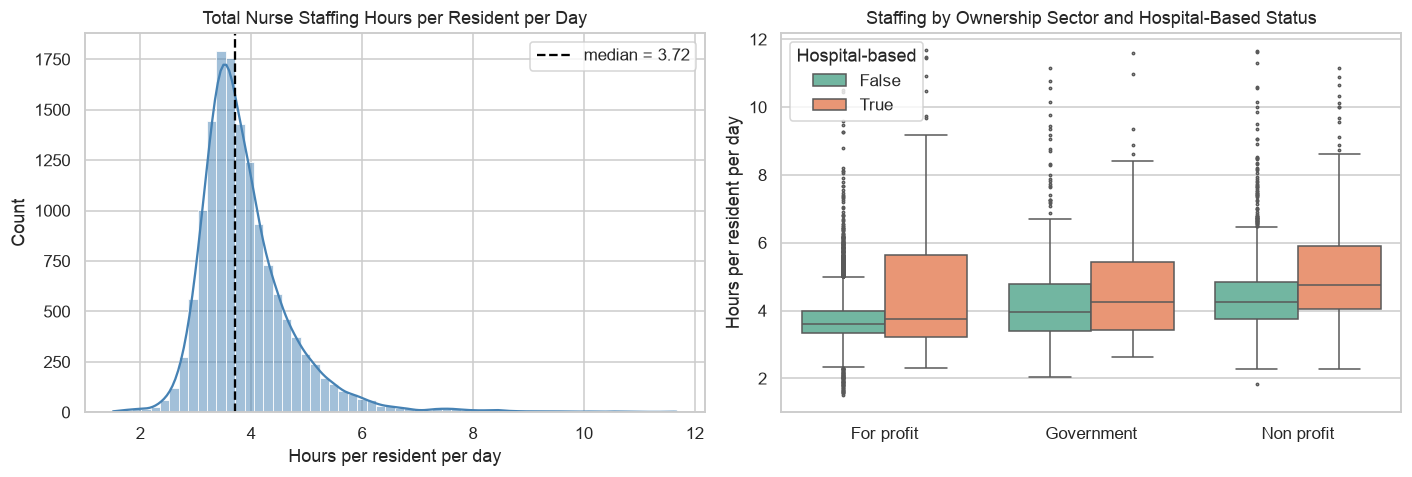

skewness of total staffing: 2.45


,count,mean,50%,std
ownership_sector,,,,
For profit,10646.0,3.73,3.61,0.71
Government,892.0,4.32,4.00,1.31
Non profit,2742.0,4.47,4.28,1.08


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(clean['total_nurse_hprd'].dropna(), bins=60, kde=True, ax=axes[0], color='steelblue')
axes[0].axvline(clean['total_nurse_hprd'].median(), color='black', linestyle='--',
                label=f"median = {clean['total_nurse_hprd'].median():.2f}")
axes[0].set_title('Total Nurse Staffing Hours per Resident per Day')
axes[0].set_xlabel('Hours per resident per day')
axes[0].legend()

sns.boxplot(data=clean, x='ownership_sector', y='total_nurse_hprd', hue='hospital_based',
            ax=axes[1], palette='Set2', fliersize=1.5)
axes[1].set_title('Staffing by Ownership Sector and Hospital-Based Status')
axes[1].set_xlabel('')
axes[1].set_ylabel('Hours per resident per day')
axes[1].legend(title='Hospital-based')
plt.tight_layout()
plt.show()

print('skewness of total staffing:', round(clean['total_nurse_hprd'].skew(), 2))
clean.groupby('ownership_sector')['total_nurse_hprd'].describe()[['count', 'mean', '50%', 'std']].round(2)

**Insight:** The median facility provides 3.72 hours of nursing care per resident per day. The distribution is right-skewed (skewness 2.45), with a long tail of facilities staffing at 6 to 11 hours. Non-profit facilities have a median of 4.28 hours versus 3.61 for for-profit facilities, a gap of about 40 minutes of nursing care per resident every day. Hospital-based units staff higher and vary much more within every sector. For Deliverable 2, the skew suggests modeling the logarithm of staffing or checking residuals carefully, and ownership sector and hospital-based status are clear candidate predictors.

### 5.3 Does staffing relate to quality?

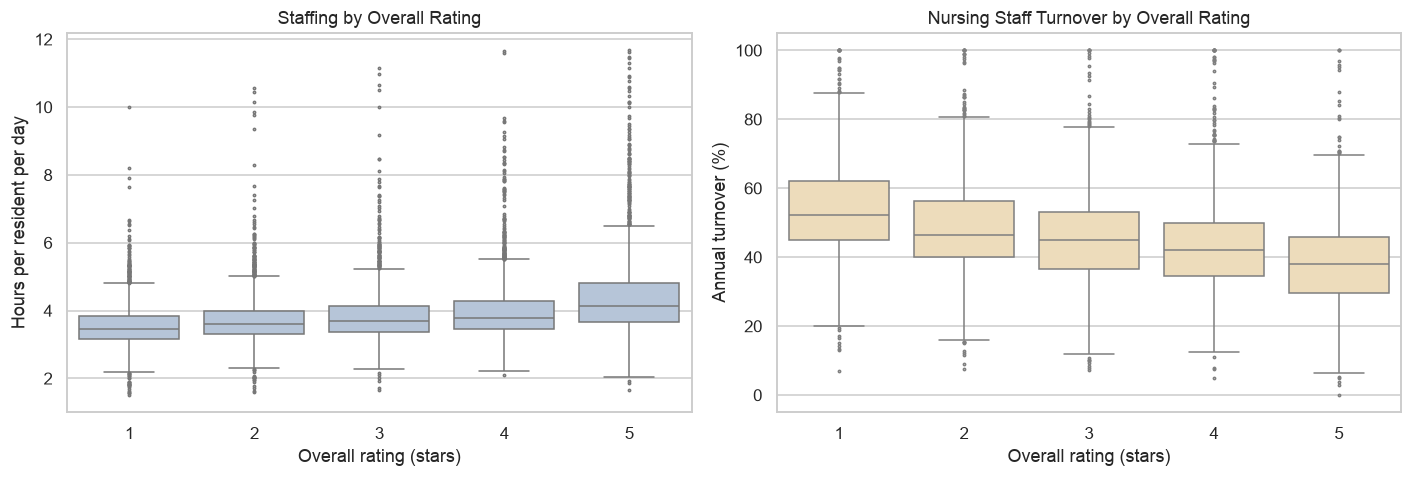

,total_nurse_hprd,rn_hprd,nurse_turnover
overall_rating,,,
1,3.47,0.46,52.10
2,3.59,0.54,46.30
3,3.68,0.57,45.05
4,3.79,0.62,42.20
5,4.15,0.78,38.10


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(data=clean, x='overall_rating', y='total_nurse_hprd', ax=axes[0], color='lightsteelblue', fliersize=1.5)
axes[0].set_title('Staffing by Overall Rating')
axes[0].set_xlabel('Overall rating (stars)')
axes[0].set_ylabel('Hours per resident per day')

sns.boxplot(data=clean, x='overall_rating', y='nurse_turnover', ax=axes[1], color='wheat', fliersize=1.5)
axes[1].set_title('Nursing Staff Turnover by Overall Rating')
axes[1].set_xlabel('Overall rating (stars)')
axes[1].set_ylabel('Annual turnover (%)')
plt.tight_layout()
plt.show()

clean.groupby('overall_rating')[['total_nurse_hprd', 'rn_hprd', 'nurse_turnover']].median().round(2)

**Insight:** Staffing rises steadily with quality. Median total staffing grows from 3.47 hours at 1 star to 4.15 hours at 5 stars, and registered nurse hours grow by about 70% (0.46 to 0.78). Annual nursing staff turnover falls from 52.1% at 1-star facilities to 38.1% at 5-star facilities. The relationship is real but modest: the correlation between total staffing and the overall rating is 0.32. **Modeling caution:** the staffing rating is calculated from these same staffing hours, and the overall rating includes the staffing rating. Using either rating to predict staffing in Deliverable 2 would leak the answer into the model, so both will be excluded as features for that task.

### 5.4 The abuse icon: the Deliverable 3 classification target

facilities with the abuse icon: 1393 of 14620 (9.5%)


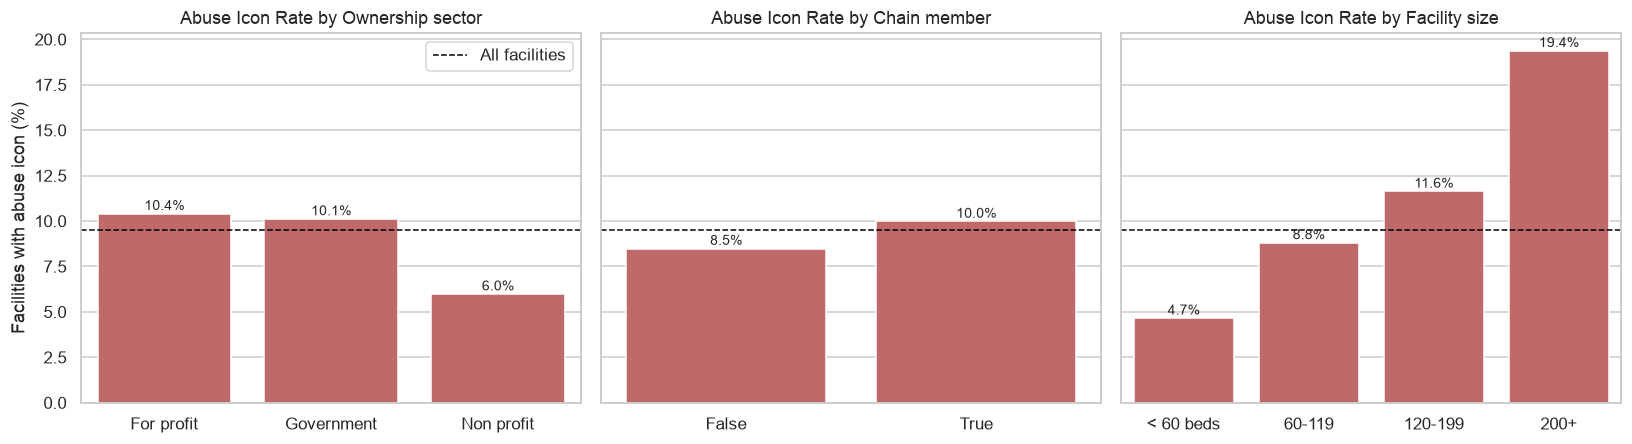

In [38]:
abuse_rate = clean['abuse_icon'].mean()
print(f"facilities with the abuse icon: {clean['abuse_icon'].sum()} of {len(clean)} ({abuse_rate:.1%})")

clean['size_band'] = pd.cut(clean['beds'], bins=[0, 60, 120, 200, np.inf],
                            labels=['< 60 beds', '60-119', '120-199', '200+'], right=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, col, title in zip(axes,
                          ['ownership_sector', 'chain_member', 'size_band'],
                          ['Ownership sector', 'Chain member', 'Facility size']):
    rates = clean.groupby(col, observed=True)['abuse_icon'].mean() * 100
    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, color='indianred')
    ax.axhline(abuse_rate * 100, color='black', linestyle='--', linewidth=1, label='All facilities')
    ax.set_title(f'Abuse Icon Rate by {title}')
    ax.set_xlabel('')
    ax.set_ylabel('Facilities with abuse icon (%)')
    for i, v in enumerate(rates.values):
        ax.text(i, v + 0.2, f'{v:.1f}%', ha='center', fontsize=9)
axes[0].legend()
plt.tight_layout()
plt.show()

In [39]:
# compare facilities with and without the abuse icon on key measures
compare_cols = ['overall_rating', 'total_nurse_hprd', 'rn_hprd', 'nurse_turnover',
                'deficiencies_recent', 'fines_dollars', 'beds', 'occupancy_rate']
clean.groupby('abuse_icon')[compare_cols].median().T.round(2)

abuse_icon,False,True
overall_rating,3.0,2.0
total_nurse_hprd,3.735715,3.55305
rn_hprd,0.59703,0.52982
nurse_turnover,44.6,47.5
deficiencies_recent,7.0,14.0
fines_dollars,0.0,37440.0
beds,99.0,119.0
occupancy_rate,0.855665,0.830949


**Insight:** Only 9.5% of facilities carry the abuse icon, so the classes are imbalanced. A model that always predicted "no abuse" would be 90.5% accurate and useless, which is why Deliverable 3 will rely on F1 score and the ROC curve, stratified train/test splits, and class weighting rather than accuracy. Facility size shows the strongest pattern, rising from 4.7% for facilities under 60 beds to 19.4% for those with 200 or more. Part of that is exposure (more residents means more chances for an incident to be cited), so size will need careful interpretation. Non-profit facilities carry the icon at 6.0%, compared with 10.4% for for-profit facilities. Flagged facilities have twice as many recent deficiencies (median 14 vs. 7) and a median of $37,440 in fines versus $0. Those inspection measures come from the same surveys that produce the abuse citation, so Deliverable 3 will compare models with and without them to separate prediction from restating the inspection results.

### 5.5 Inspections and fines

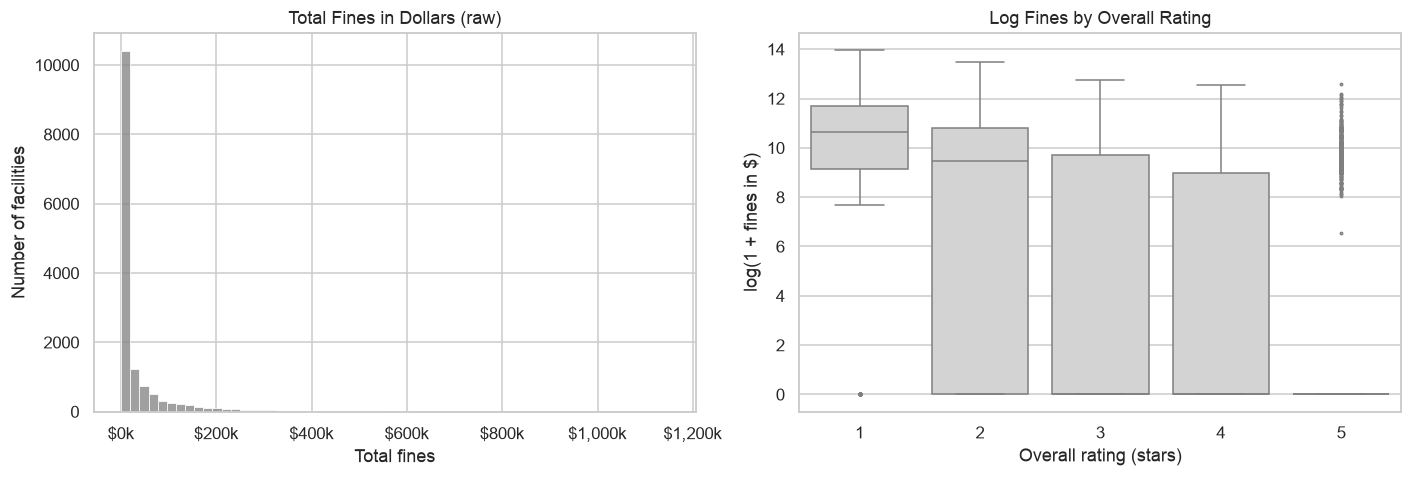

facilities with any fine: 6448 (44.1%)
median fine among fined facilities: $33,520
largest total fines: $1,148,809


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(clean['fines_dollars'], bins=60, ax=axes[0], color='gray')
axes[0].set_title('Total Fines in Dollars (raw)')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v / 1000:,.0f}k'))
axes[0].set_xlabel('Total fines')
axes[0].set_ylabel('Number of facilities')

sns.boxplot(data=clean, x='overall_rating', y='log_fines_dollars', ax=axes[1], color='lightgray', fliersize=1.5)
axes[1].set_title('Log Fines by Overall Rating')
axes[1].set_xlabel('Overall rating (stars)')
axes[1].set_ylabel('log(1 + fines in $)')
plt.tight_layout()
plt.show()

fined = clean['fines_dollars'] > 0
print(f"facilities with any fine: {fined.sum()} ({fined.mean():.1%})")
print(f"median fine among fined facilities: ${clean.loc[fined, 'fines_dollars'].median():,.0f}")
print(f"largest total fines: ${clean['fines_dollars'].max():,.0f}")

**Insight:** 44.1% of facilities have been fined at least once in the reporting window. Among them, the median total is $33,520, and the largest total reaches $1,148,809. The raw distribution is so skewed (skewness 4.3) that almost every facility sits in the first bar. After the log transform the skewness drops to 0.3, and a clear gradient appears: fines fall steadily as ratings rise, and most 5-star facilities have no fines at all. The log version will be used in modeling and clustering, so a few extreme facilities do not dominate distance calculations.

### 5.6 Feature relationships

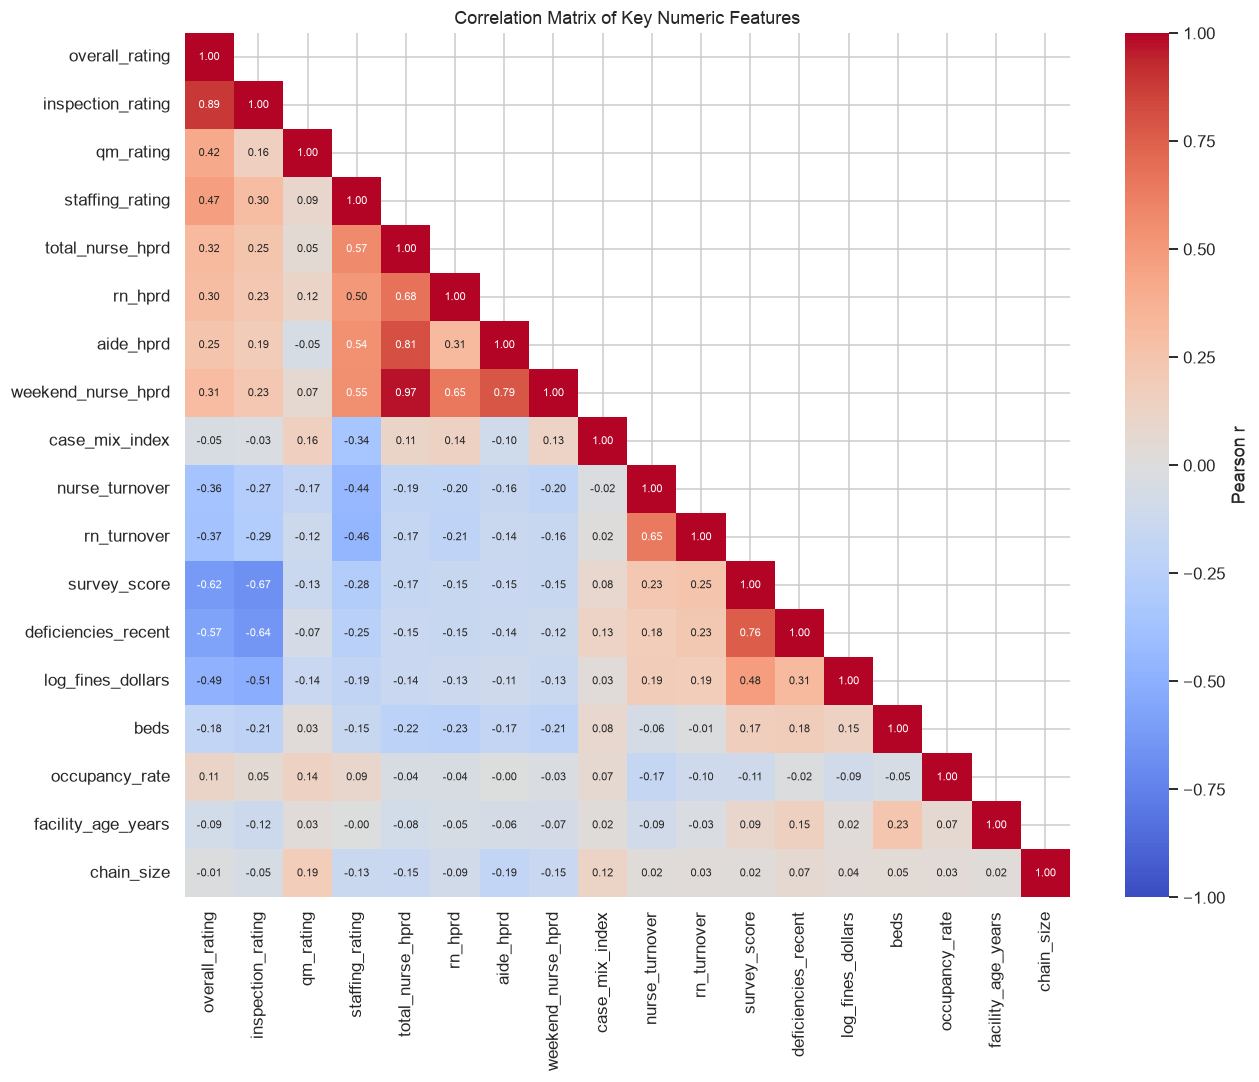

In [41]:
corr_cols = ['overall_rating', 'inspection_rating', 'qm_rating', 'staffing_rating',
             'total_nurse_hprd', 'rn_hprd', 'aide_hprd', 'weekend_nurse_hprd', 'case_mix_index',
             'nurse_turnover', 'rn_turnover', 'survey_score', 'deficiencies_recent',
             'log_fines_dollars', 'beds', 'occupancy_rate', 'facility_age_years', 'chain_size']
corr = clean[corr_cols].corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            annot_kws={'size': 7}, cbar_kws={'label': 'Pearson r'})
plt.title('Correlation Matrix of Key Numeric Features')
plt.tight_layout()
plt.show()

In [42]:
# strongest pairs, ignoring the diagonal
pairs = (corr.where(~np.tril(np.ones_like(corr, dtype=bool)))
             .stack().rename('r').reset_index()
             .assign(abs_r=lambda t: t['r'].abs())
             .sort_values('abs_r', ascending=False))
pairs.head(10).round(2)

,level_0,level_1,r,abs_r
79,total_nurse_hprd,weekend_nurse_hprd,0.97,0.97
1,overall_rating,inspection_rating,0.89,0.89
78,total_nurse_hprd,aide_hprd,0.81,0.81
115,aide_hprd,weekend_nurse_hprd,0.79,0.79
210,survey_score,deficiencies_recent,0.76,0.76
77,total_nurse_hprd,rn_hprd,0.68,0.68
29,inspection_rating,survey_score,-0.67,0.67
97,rn_hprd,weekend_nurse_hprd,0.65,0.65
172,nurse_turnover,rn_turnover,0.65,0.65
30,inspection_rating,deficiencies_recent,-0.64,0.64


**Insight:** Several feature groups are almost redundant. Total and weekend staffing correlate at 0.97, the overall and inspection ratings at 0.89 (the overall rating is built from the inspection rating), and total staffing and nurse aide hours at 0.81, because aides provide most of the hours. This multicollinearity is the main reason Deliverable 2 will compare ordinary linear regression with Ridge and Lasso, which are designed to handle correlated predictors, and why only one variable from each redundant group will be kept for clustering. Turnover is moderately negative with every rating (about −0.36 with the overall rating). Structural features such as beds, facility age, and chain size are only weakly correlated with quality on their own, so any value they add will likely come through combinations with other features.

### 5.7 Geography

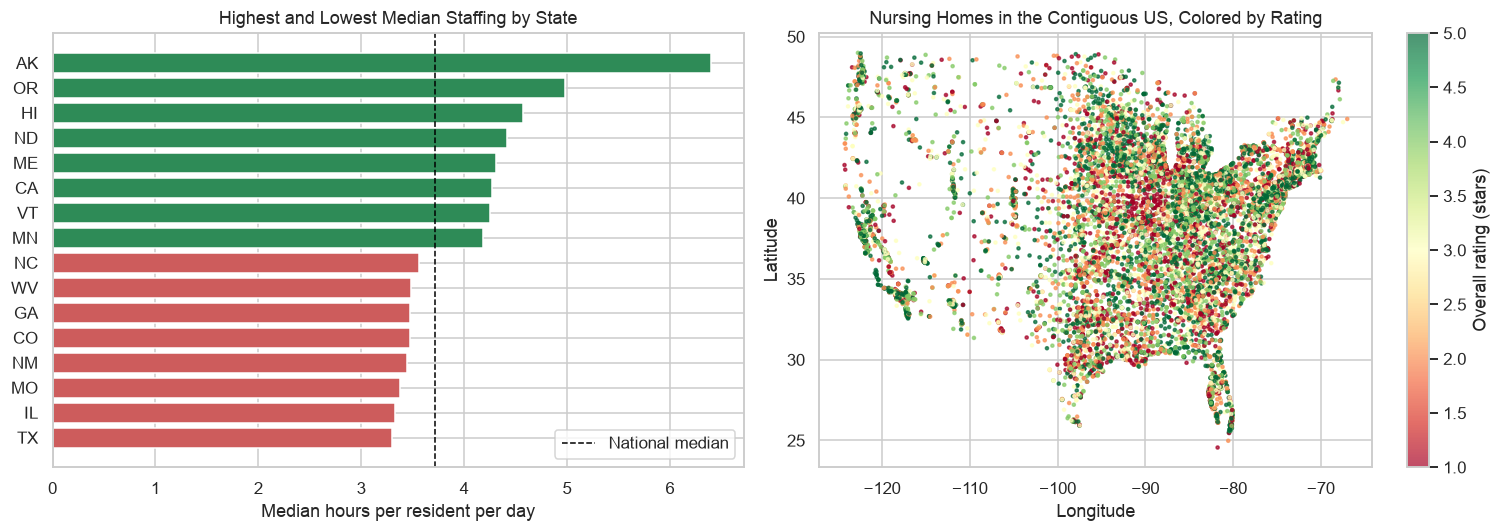

,facilities,median_hprd,mean_rating,abuse_rate
state,,,,
TX,1170,3.30,2.76,0.09
IL,656,3.33,2.58,0.29
MO,486,3.38,2.62,0.14
NM,68,3.44,2.94,0.18
CO,210,3.47,3.12,0.25
GA,354,3.47,2.72,0.06
WV,123,3.48,3.08,0.07
NC,419,3.57,3.01,0.07
MN,337,4.18,3.19,0.07


In [43]:
state_stats = (clean.groupby('state')
                    .agg(facilities=('ccn', 'count'),
                         median_hprd=('total_nurse_hprd', 'median'),
                         mean_rating=('overall_rating', 'mean'),
                         abuse_rate=('abuse_icon', 'mean'))
                    .query('facilities >= 20'))

top_bottom = pd.concat([state_stats.nlargest(8, 'median_hprd'), state_stats.nsmallest(8, 'median_hprd')])
top_bottom = top_bottom.sort_values('median_hprd')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['indianred' if v < clean['total_nurse_hprd'].median() else 'seagreen' for v in top_bottom['median_hprd']]
axes[0].barh(top_bottom.index, top_bottom['median_hprd'], color=colors)
axes[0].axvline(clean['total_nurse_hprd'].median(), color='black', linestyle='--', linewidth=1, label='National median')
axes[0].set_title('Highest and Lowest Median Staffing by State')
axes[0].set_xlabel('Median hours per resident per day')
axes[0].legend()

lower48 = clean[(clean['longitude'] > -125) & (clean['longitude'] < -66) & (clean['latitude'] > 24) & (clean['latitude'] < 50)]
sc = axes[1].scatter(lower48['longitude'], lower48['latitude'], c=lower48['overall_rating'],
                     cmap='RdYlGn', s=4, alpha=0.7)
plt.colorbar(sc, ax=axes[1], label='Overall rating (stars)')
axes[1].set_title('Nursing Homes in the Contiguous US, Colored by Rating')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
plt.tight_layout()
plt.show()

top_bottom.round(2)

In [44]:
# states with the highest and lowest share of facilities carrying the abuse icon
abuse_by_state = state_stats.sort_values('abuse_rate', ascending=False)[['facilities', 'abuse_rate', 'mean_rating']]
pd.concat([abuse_by_state.head(6), abuse_by_state.tail(6)]).assign(abuse_rate=lambda t: (t['abuse_rate'] * 100).round(1)).round(2)

,facilities,abuse_rate,mean_rating
state,,,
IL,656,28.8,2.58
WY,36,27.8,2.8
AZ,139,26.6,3.4
CO,210,25.2,3.12
CT,190,23.2,3.02
DE,44,18.2,3.21
KY,266,1.5,3.02
MA,341,1.5,3.11
NE,178,0.6,2.92


**Insight:** Geography matters on two levels. Median staffing ranges from 3.30 hours per resident in Texas to 6.40 in Alaska, and the low-staffing states (Texas, Illinois, Missouri, New Mexico, Colorado, Georgia) cluster in the South and Midwest. The map shows the same pattern, with dense pockets of 1- and 2-star facilities across Texas, Oklahoma, Missouri, and Illinois. Abuse icon rates vary far more than care quality alone would explain: 28.8% of Illinois facilities and 25.2% of Colorado facilities carry the icon, while Maine, New Hampshire, and Hawaii have none. Because the icon depends on what state inspectors cite, some of this variation likely reflects differences in how state survey agencies inspect and document, not only differences in care. State will be included as a feature in Deliverable 3, and this inspection-practice bias will be a central topic in the Deliverable 4 ethics discussion.

## 6. Insights and How They Guide the Modeling Steps

### Key findings

1. **Ownership is the strongest single pattern in the data.** Compared with non-profit facilities, for-profit facilities staff about 40 fewer minutes per resident per day (3.61 vs. 4.28 median hours), are twice as likely to have 1 star (21.7% vs. 9.9%), and are more likely to carry the abuse icon (10.4% vs. 6.0%).
2. **Staffing and stability track quality.** Moving from 1 to 5 stars, median staffing rises from 3.47 to 4.15 hours, RN hours rise by about 70%, and turnover drops from 52.1% to 38.1%.
3. **Size is linked to abuse citations.** The abuse icon rate rises from 4.7% in the smallest facilities to 19.4% in the largest.
4. **Ratings and citations depend on the state.** Inspection ratings are graded within each state, and abuse icon rates range from 0% to 28.8% across states.

### How these insights guide the next deliverables

| Deliverable | Plan informed by the EDA |
|---|---|
| **2. Regression** | Target: `total_nurse_hprd`. The 340 facilities without valid staffing data are dropped rather than imputed. Staffing and overall ratings are excluded as features to prevent leakage. The right skew (2.45) suggests a log-transformed target. Strong correlations among predictors (up to 0.97) justify comparing linear regression with Ridge and Lasso. Candidate features: ownership sector and form, hospital-based status, chain membership and size, beds, occupancy, case-mix index, turnover, state, and urban status. |
| **3. Classification** | Target: `abuse_icon` (9.5% positive). The imbalance calls for stratified splits, class weights, and evaluation by F1 and ROC/AUC rather than accuracy. Models will be compared with and without inspection-derived features (deficiencies, fines) to check whether they are predicting abuse or simply restating the inspection results. |
| **3. Clustering** | Features: staffing (one measure per correlated group), turnover, log fines, occupancy, size, and ratings, all standardized. The sector differences suggest clusters will partly align with ownership, which gives a useful check on whether the segments make sense. |
| **3. Association rules** | Items: ownership sector, chain membership, size band, staffing level (binned at quartiles), turnover level, rating level, and the abuse icon. Example rule to test: {for profit, low staffing, high turnover} → {1-2 stars}. |
| **4. Ethics** | Topics surfaced already: grading relative to each state, state-to-state inspection differences in abuse citations, the profit motive in care for a vulnerable population, and the exclusion of unrated Special Focus Facilities, which are the worst performers and are therefore missing from any model trained on ratings. |

## 7. Summary

The October 2026 CMS Provider Information file (14,686 nursing homes, 102 attributes) was cleaned into an analysis-ready dataset of **14,620 facilities and 42 columns**, saved as `data/nh_cleaned.csv`.

* **Duplicates:** none at the row or facility level. Sixteen facilities share an address, but they are separately certified units and were kept.
* **Inconsistencies corrected:** ZIP codes that lost leading zeros (1,145), mixed text case (5,126 names) and double spaces (76 names), Y/N text converted to booleans, ownership type split into sector and legal form, a "Data Not Available" placeholder, and text dates.
* **Missing values:** handled by reason, not by column. Footnote codes explained every missing rating and staffing value; ratings and the staffing target were left missing rather than invented; structurally blank fields were filled with meaningful constants; a 93%-empty column was dropped; turnover was median-imputed within ownership sector with flag columns; and 66 rows with no size data (0.45%) were removed.
* **Noisy data:** 32 impossible occupancy values (over 120% of capacity) and 32 implausible staffing values (under 1.5 or over 12 hours) were set to missing. Legitimate high-staffing outliers were kept, and log transforms were added for skewed fines and inspection scores.

The EDA shows that ownership sector, staffing, turnover, facility size, and state are the dominant patterns, and it identified leakage risks, class imbalance, and multicollinearity that the modeling deliverables will need to handle.